<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/7_Object_Detection_using_YOLO_Flowers_detection_https_www_kaggle_com_datasets_imsparsh_flowers_dataset_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ultralytics kagglehub
import kagglehub
path = kagglehub.dataset_download('imsparsh/flowers-dataset')
print(path)

Using Colab cache for faster access to the 'flowers-dataset' dataset.
/kaggle/input/flowers-dataset


In [ ]:
import os, glob
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')

def find_class_root(p):
    """Return the folder that directly contains the class sub-folders (each holding images)."""
    for root, dirs, files in os.walk(p):
        good = [d for d in dirs if any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(root, d)))]
        if len(good) >= 2:
            return root
    return p

import random, shutil
import matplotlib.pyplot as plt

src = find_class_root(path)
print("Class folders:", sorted(os.listdir(src)))

# YOLO classification wants:  OUT/train/<class>/*.jpg  and  OUT/val/<class>/*.jpg   -> make an 80/20 split
OUT = 'flowers_yolo'
random.seed(0); val_files = []
for cls in sorted(d for d in os.listdir(src) if os.path.isdir(os.path.join(src, d))):
    files = [f for f in glob.glob(f'{src}/{cls}/*') if f.lower().endswith(IMG_EXT)]
    random.shuffle(files); n = int(0.8 * len(files))
    for split, fl in (('train', files[:n]), ('val', files[n:])):
        os.makedirs(f'{OUT}/{split}/{cls}', exist_ok=True)
        for f in fl: shutil.copy(f, f'{OUT}/{split}/{cls}')
    val_files += files[n:]
print("train images:", len(glob.glob(f'{OUT}/train/*/*')), " val images:", len(glob.glob(f'{OUT}/val/*/*')))

Class folders: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
train images: 2194  val images: 552


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n-cls.pt')         # small pre-trained YOLOv8 classification model
results = model.train(data=os.path.abspath(OUT), epochs=5, imgsz=128, batch=32)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/flowers_yolo, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=No

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-cls summary (fused): 30 layers, 1,441,285 parameters, 0 gradients, 3.3 GFLOPs
train: /content/flowers_yolo/train... found 2194 images in 5/5 classes ✅ 
val: /content/flowers_yolo/val... found 552 images in 5/5 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1383.1±814.9 MB/s, size: 75.0 KB)
val: Scanning /content/flowers_yolo/val... 552 images, 0 corrupt: 100% ━━━━━━━━━━━━ 552/552 105.2Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 35/35 6.6it/s 5.3s
                   all      0.938          1
Speed: 0.0ms preprocess, 4.6ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
Top-1 accuracy: 0.9384058117866516  Top-5 accuracy: 1.0


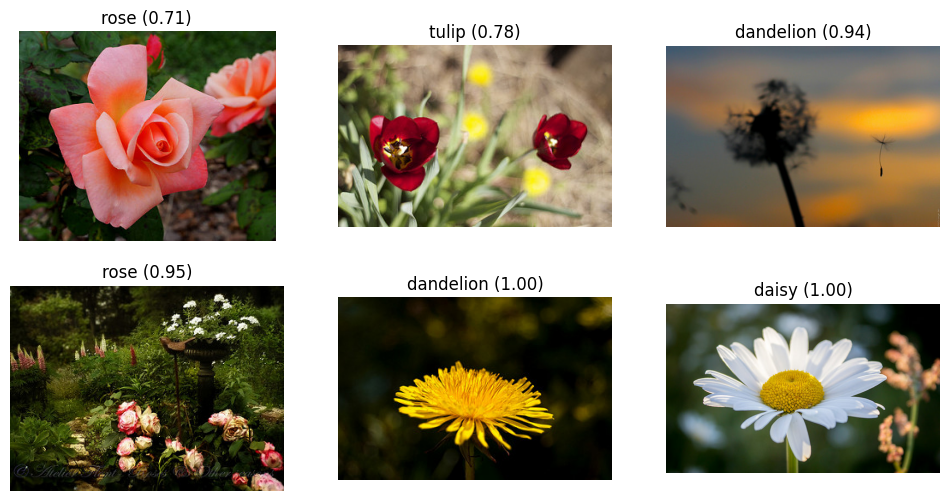

In [ ]:
# Evaluate + predict
metrics = model.val()
print("Top-1 accuracy:", metrics.top1, " Top-5 accuracy:", metrics.top5)

plt.figure(figsize=(12, 6))
for i, f in enumerate(random.sample(val_files, 6)):
    r = model.predict(f, verbose=False)[0]
    plt.subplot(2, 3, i + 1); plt.imshow(plt.imread(f)); plt.axis('off')
    plt.title(f"{r.names[r.probs.top1]} ({float(r.probs.top1conf):.2f})")
plt.show()

In [ ]:
import shutil
# OPTIONAL: make a real "detection" dataset where each image gets ONE box covering the whole image
# (use this only if the examiner insists on bounding boxes; the dataset has no real box annotations)
def make_fullbox_dataset(split_root, out_root):
    classes = sorted(os.listdir(os.path.join(split_root, 'train')))
    for split in ('train', 'val'):
        os.makedirs(f'{out_root}/images/{split}', exist_ok=True); os.makedirs(f'{out_root}/labels/{split}', exist_ok=True)
        for ci, c in enumerate(classes):
            for f in glob.glob(f'{split_root}/{split}/{c}/*'):
                if not f.lower().endswith(IMG_EXT): continue
                name = f'{c}_{os.path.basename(f)}'
                shutil.copy(f, f'{out_root}/images/{split}/{name}')
                open(f'{out_root}/labels/{split}/{os.path.splitext(name)[0]}.txt', 'w').write(f'{ci} 0.5 0.5 1.0 1.0\n')
    yaml_text = f"path: {os.path.abspath(out_root)}\ntrain: images/train\nval: images/val\nnames:\n" + "".join(f"  {i}: {c}\n" for i, c in enumerate(classes))
    open(f'{out_root}/data.yaml', 'w').write(yaml_text)
    return f'{out_root}/data.yaml'

# yaml_path = make_fullbox_dataset(OUT, 'flowers_det')
# det = YOLO('yolov8n.pt'); det.train(data=yaml_path, epochs=5, imgsz=320, batch=16)
# r = det.predict(random.choice(val_files), conf=0.25)[0]; plt.imshow(r.plot()[..., ::-1]); plt.axis('off'); plt.show()


In [ ]:
Problem statement: "Object Detection using YOLO. Flowers detection: kaggle.com/datasets/imsparsh/flowers-dataset"

1. What is the problem?

We have flower photos (daisy, dandelion, rose, sunflower, tulip). The computer must recognise the flower in each image using YOLO.

2. First, what is YOLO?

YOLO = "You Only Look Once". It is a very fast AI model for object detection. An older detector looked at an image thousands of times (once for every region that might hold an object). YOLO looks at the whole image once and directly outputs the answer.

Classification vs detection (examiners love this):

Task	Output	Example
Classification	One label for the whole image	"This image is a rose"
Detection	A box + label + confidence for every object	"Rose at this position, 92% sure"

We use YOLOv8 from the Ultralytics library. It comes in sizes (n = nano, s, m, l, x). We use the smallest, nano (n), because it is fast and fits in Colab.

3. The honest part you must know

The flowers dataset has only image-level labels: images are sorted into folders named daisy, rose, and so on. It has no bounding boxes (no rectangle showing where the flower is). Real object detection needs boxes.

So we use YOLOv8 in classification mode (yolov8n-cls). It uses the same YOLO family and backbone, but the output is the flower type, not boxes. This is the right choice for this dataset.

If the examiner asks: "The dataset has class labels only and no bounding-box annotations, so I used YOLOv8's classification mode. If the dataset had box labels, I'd use the detection model (yolov8n.pt) in exactly the same way."

I also added an optional cell at the end of Program 7. It makes one box that covers the whole image for each photo and trains the detection model. That draws boxes, but they are artificial, because they simply cover the whole image. Use it only if the examiner insists on seeing boxes, and say plainly what it is.

4. How the model works (architecture)

YOLOv8-cls is built in two parts:

Part	What it does
Backbone	A stack of Conv layers and C2f blocks (the YOLOv8 feature-extraction building block). It finds edges, then textures, then flower shapes.
Classify head	A Conv layer, global average pooling, then a Linear layer with softmax, which gives probabilities for the 5 flower classes.

Flow: Input image → stem convolutions → backbone (Conv + C2f) → classify head → softmax → flower class.

The model starts as yolov8n-cls.pt, pre-trained on ImageNet, so it already knows a lot about shapes and textures. We only fine-tune it on our flowers. This is transfer learning, as in Problem 2.

########CODE##########
Step 1: Install and download

python
!pip -q install ultralytics kagglehub
path = kagglehub.dataset_download('imsparsh/flowers-dataset')

ultralytics is the library that contains YOLOv8.

Step 2: Prepare the folders

python
src = find_class_root(path)
OUT = 'flowers_yolo'
# for each flower class: shuffle images, 80% -> OUT/train/<class>, 20% -> OUT/val/<class>

YOLO classification needs train/<class>/images and val/<class>/images. The code makes an 80/20 split and copies the images there.

Step 3: Train

python
from ultralytics import YOLO
model = YOLO('yolov8n-cls.pt')
results = model.train(data=os.path.abspath(OUT), epochs=5, imgsz=128, batch=32)
yolov8n-cls.pt: the small pre-trained classification model.
epochs=5: five passes over the data.
imgsz=128: images are resized to 128×128 (faster).
batch=32: 32 images per update.

Step 4: Evaluate and predict

python
metrics = model.val()
print("Top-1 accuracy:", metrics.top1, " Top-5 accuracy:", metrics.top5)
r = model.predict(f)[0]
r.names[r.probs.top1]    # predicted flower name
Top-1 accuracy: the model's single best guess is correct.
Top-5 accuracy: the correct class is among its top 5 guesses. With only 5 classes this is always 100%, so top-1 is the number to quote.
The last cell shows 6 flower images with the predicted name and confidence.
6. The output you will see
Ultralytics prints its version and device (CPU or GPU).
train: ... found N images in 5 classes, and the same for val.
The model structure, with about 1.4 million parameters.
A training table for each epoch: loss falling and accuracy_top1 rising.
Files saved in runs/classify/train (best.pt, last.pt, graphs and results.csv).
Top-1 accuracy of about 85–93% after 5 epochs. I haven't run it on the real dataset, so go by your own number.
Six flower images with name (confidence) titles.

###########BLOCK##############
          START
            |
            v
      Load Flower Dataset
            |
            v
       Prepare Dataset
        Train / Val
            |
            v
      Load YOLOv8 Model
       (yolov8n-cls.pt)
            |
            v
        Preprocessing
            |
            v
       Feature Extraction
          (Backbone)
            |
            v
     Classification Head
            |
            v
        Train Model
            |
            v
       Validate Model
            |
            v
      Predict Flower Class
            |
            v
           STOP

#########QUE$#############
What is YOLO? A single-stage, real-time object detector that predicts boxes and classes in one pass of the network.
Why "You Only Look Once"? Older detectors (like R-CNN) examined thousands of regions one by one. YOLO processes the whole image once, so it is much faster.
Classification vs detection? Classification gives one label per image. Detection gives a box, a label and a confidence for each object.
Why classification mode here? The dataset has no bounding-box labels, only folder labels.
What is a pre-trained model? A model already trained on a large dataset (ImageNet or COCO), so we only fine-tune it. It saves time and gives better accuracy.
What does n mean in yolov8n? Nano, the smallest and fastest variant. Others are s, m, l and x.
Top-1 vs top-5 accuracy? Top-1: the best guess is correct. Top-5: the correct class is in the 5 best guesses.
What is imgsz? The size images are resized to before training.
Where are results saved? In runs/classify/train, with best.pt as the best weights.
How would you get real boxes? Label the images with a tool such as LabelImg or Roboflow, save them in YOLO format, and train yolov8n.pt.